In [1]:
import json
import numpy as np
import matplotlib.pyplot as plt

In [2]:
def compute_mean_roc(fpr_list, tpr_list, auc_list, n_points=200):
    mean_fpr = np.linspace(0, 1, n_points)
    interp_tprs = []

    for fpr, tpr in zip(fpr_list, tpr_list):
        interp_tpr = np.interp(mean_fpr, fpr, tpr)
        interp_tpr[0] = 0.0
        interp_tprs.append(interp_tpr)

    mean_tpr = np.mean(interp_tprs, axis=0)
    mean_tpr[-1] = 1.0
    std_tpr = np.std(interp_tprs, axis=0)

    mean_auc = np.mean(auc_list)
    std_auc = np.std(auc_list)

    return mean_fpr, mean_tpr, std_tpr, mean_auc, std_auc

In [3]:
def plot_combined_roc(model_results: dict, figsize=(6, 6)):
    colors     = ["#0072B2", "#D55E00", "#009E73", "#CC79A7"]
    linestyles = ["-",       "--",      "-.",      ":"]

    fig, ax = plt.subplots(figsize=figsize)

    for (model_name, data), color, ls in zip(model_results.items(), colors, linestyles):
        mean_fpr, mean_tpr, std_tpr, mean_auc, std_auc = compute_mean_roc(
            data["fpr_list"], data["tpr_list"], data["auc_list"]
        )
        ax.plot(
            mean_fpr, mean_tpr,
            color=color, lw=2, linestyle=ls,
            label=f"{model_name}  AUC = {mean_auc:.3f} ± {std_auc:.3f}"
        )
        ax.fill_between(
            mean_fpr,
            np.clip(mean_tpr - std_tpr, 0, 1),
            np.clip(mean_tpr + std_tpr, 0, 1),
            color=color, alpha=0.15
        )

    ax.plot([0, 1], [0, 1], "k:", lw=1, label="Chance (AUC = 0.500)")
    ax.set(
        xlabel="False Positive Rate (1 – Specificity)",
        ylabel="True Positive Rate (Sensitivity)",
        xlim=[-0.01, 1.01],
        ylim=[-0.01, 1.01],
    )
    ax.legend(loc="lower right", framealpha=0.9, fontsize=9)
    ax.set_aspect("equal")
    fig.tight_layout()
    return fig

# Combined ROC curves (seeds 7–11)

Mean ROC ± 1 std across seeds for the four models.


## GS7 (cspca_threshold 7.0)

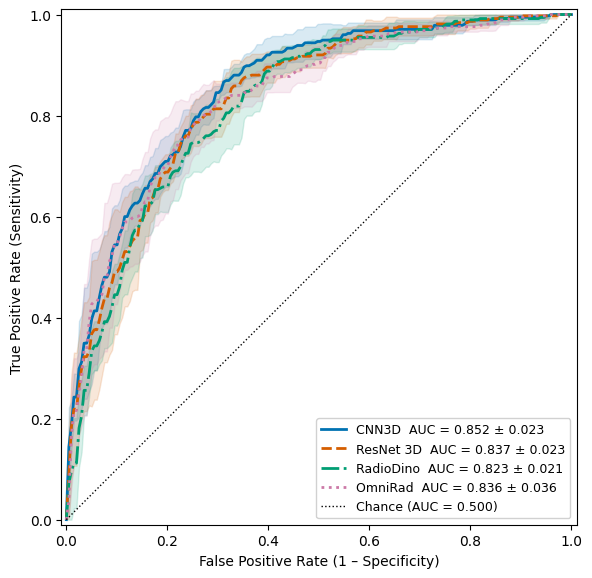

In [4]:
model_files = {
    "CNN3D": "../results/roc_jsons/3DCNN-pg_thr7_s7-11_roc.json",
    "ResNet 3D": "../results/roc_jsons/ResNet3D-pg_thr7_s7-11_roc.json",
    "RadioDino": "../results/roc_jsons/RadioDino-pg_thr7_s7-11_roc.json",
    "OmniRad": "../results/roc_jsons/OmniRad-pg_thr7_s7-11_roc.json",
}

model_results = {}
for model_name, path in model_files.items():
    with open(path) as f:
        data = json.load(f)
    
    model_results[model_name] = {
        "fpr_list": [np.array(seed["fpr"]) for seed in data.values()],
        "tpr_list": [np.array(seed["tpr"]) for seed in data.values()],
        "auc_list": [seed["auc"] for seed in data.values()],
    }

fig = plot_combined_roc(model_results)
plt.show()
# fig.savefig("roc_combined.pdf", dpi=300, bbox_inches="tight")

## GS6 (cspca_threshold 6.0)

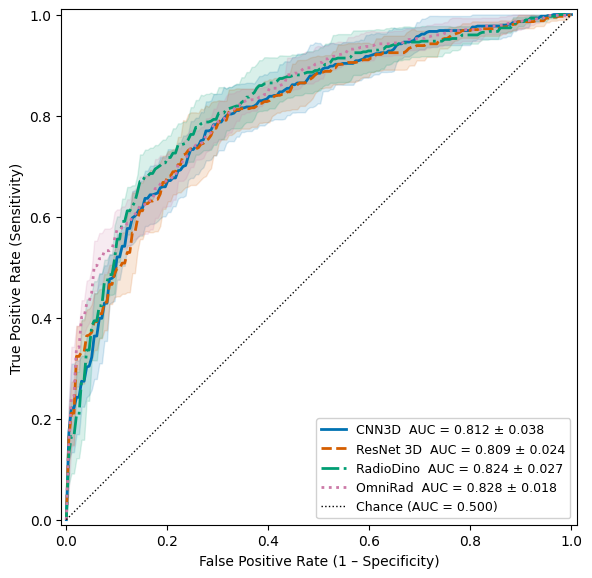

In [5]:
model_files = {
    "CNN3D": "../results/roc_jsons/3DCNN-pg_thr6_s7-11_roc.json",
    "ResNet 3D": "../results/roc_jsons/ResNet3D-pg_thr6_s7-11_roc.json",
    "RadioDino": "../results/roc_jsons/RadioDino-pg_thr6_s7-11_roc.json",
    "OmniRad": "../results/roc_jsons/OmniRad-pg_thr6_s7-11_roc.json",
}

model_results = {}
for model_name, path in model_files.items():
    with open(path) as f:
        data = json.load(f)
    
    model_results[model_name] = {
        "fpr_list": [np.array(seed["fpr"]) for seed in data.values()],
        "tpr_list": [np.array(seed["tpr"]) for seed in data.values()],
        "auc_list": [seed["auc"] for seed in data.values()],
    }

fig = plot_combined_roc(model_results)
plt.show()
# fig.savefig("roc_combined.pdf", dpi=300, bbox_inches="tight")